# B04 — Riesgo de contraparte y xVA

**Objetivos:** simular la exposición de un swap sin colateral; calcular CVA, DVA y FVA; traducirlos a puntos
básicos en el tipo del cliente; comparar mitigantes (CSA, umbral, *break*); caso del swap a 15 años de una
empresa BBB.

**Fuentes:** Myint cap. 26–31; Hull cap. 9 y 24; Gatto cap. 9 y 12. Datos sintéticos.

Todo se mide desde el **banco**: un valor positivo significa que la empresa le debe dinero al banco.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # notebooks/ -> repository root
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

from derivlab.market import sample_market
from derivlab.curves import build_curves, discount_t
from derivlab.scenarios import HullWhite
from derivlab.xva import (swap_value_paths, exposure_profile, xva, mpor_exposure, remaining_annuity,
                          survival, to_running_bp)

m = sample_market()
estr, eur = build_curves(m)
hw = HullWhite(estr, eur, a=0.03, sigma=0.0085)

## 1. El caso

**Logística Atlántica** (ficticia, BBB) financia una plataforma logística con un préstamo de 400 M€ a 15 años
a Euribor 6M y paga fijo en un swap con su banco. No tiene CSA: no intercambia colateral. Su CDS a 15 años
cotiza a 120 pb (recuperación del 40 %). El banco tiene un spread propio de 60 pb y un coste de
financiación de 50 pb sobre €STR.

El banco recibe fijo y paga Euribor. Si los tipos bajan, el swap vale a favor del banco y la empresa le debe dinero.

CASE 15y swap rate 2.833%; annuity 12.34; value at inception 0.00
CASE peak EE 19.4 M EUR at 4.75y; peak PFE 97.5% 113.8 M EUR at 4.75y


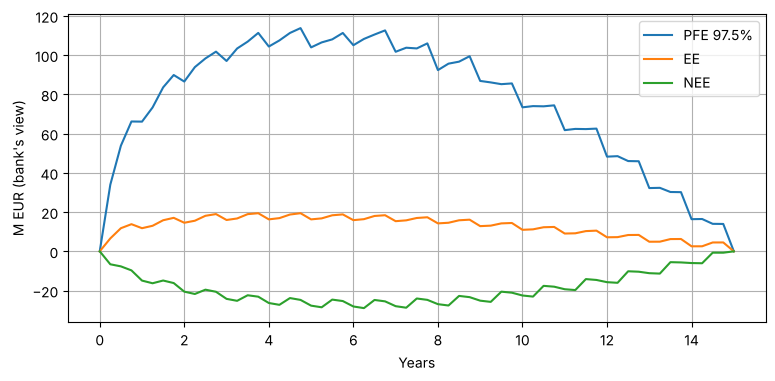

In [2]:
N, YEARS = 400e6, 15
k15, A15 = hw.swap_rate(0.0, np.zeros(1), YEARS)
k15, A15 = float(k15[0]), float(A15[0])
times, V, D = swap_value_paths(hw, N, k15, YEARS, bank_receives_fixed=True, grid_step=0.25, n_paths=6000, seed=3)
prof = exposure_profile(times, V, D)
peak = prof.loc[prof.EE.idxmax()]
print(f"CASE 15y swap rate {k15:.3%}; annuity {A15:.2f}; value at inception {V[:, 0].mean():.2f}")
print(f"CASE peak EE {peak.EE / 1e6:.1f} M EUR at {peak.t:.2f}y; peak PFE 97.5% {prof.PFE.max() / 1e6:.1f} M EUR "
      f"at {prof.t[prof.PFE.idxmax()]:.2f}y")
fig, ax = plt.subplots()
ax.plot(prof.t, prof.PFE / 1e6, label="PFE 97.5%")
ax.plot(prof.t, prof.EE / 1e6, label="EE")
ax.plot(prof.t, prof.NEE / 1e6, label="NEE")
ax.set_xlabel("Years"); ax.set_ylabel("M EUR (bank's view)"); ax.legend(); plt.show()

La exposición esperada crece al principio (difusión de los tipos) y cae al final (quedan menos flujos). Como la
curva es creciente, el banco cobra más de lo que paga en los primeros años, así que después el swap tiende a
valer a favor de la empresa: la NEE es mayor que la EE.

## 2. CVA, DVA y FVA

```
CVA = (1 - R) · Σ EE*(t) · [S(t_{i-1}) - S(t_i)]      S(t) = exp(-λt),  λ = spread / (1 - R)
DVA = (1 - R_banco) · Σ NEE*(t) · ΔPD_banco
FCA = s_f · Σ EE*(t) Δt        FBA = s_f · Σ NEE*(t) Δt
```

EE* es la exposición descontada por camino. Para el cliente, el coste se expresa en puntos básicos sobre el
tipo fijo dividiendo por N × anualidad.

In [3]:
res = xva(prof, cpty_spread=0.012, bank_spread=0.006, funding_spread=0.005)
tbl = pd.DataFrame({"eur": res}).T
bp = {k: to_running_bp(v, N, A15) for k, v in res.items()}
print(pd.DataFrame({"M_EUR": {k: v / 1e6 for k, v in res.items()}, "running_bp": bp}).round(2))
charge_bp = bp["CVA"] + bp["FCA"]
print(f"CASE CVA {res['CVA'] / 1e6:.2f} M EUR ({bp['CVA']:.1f} bp); FCA {res['FCA'] / 1e6:.2f} M EUR ({bp['FCA']:.1f} bp); "
      f"DVA {res['DVA'] / 1e6:.2f} M; FBA {res['FBA'] / 1e6:.2f} M")
print(f"CASE charge if the bank passes on CVA + FCA only: {charge_bp:.1f} bp -> client rate {k15 + charge_bp * 1e-4:.3%}")

     M_EUR  running_bp
CVA   1.93        3.90
DVA   1.25        2.53
FCA   0.91        1.84
FBA   1.11        2.25
CASE CVA 1.93 M EUR (3.9 bp); FCA 0.91 M EUR (1.8 bp); DVA 1.25 M; FBA 1.11 M
CASE charge if the bank passes on CVA + FCA only: 5.7 bp -> client rate 2.891%


### Sensibilidad al rating de la empresa

In [4]:
rows = []
for rating, spread in [("A", 0.0070), ("BBB", 0.0120), ("BB", 0.0250), ("B", 0.0450)]:
    r = xva(prof, cpty_spread=spread)
    rows.append({"rating": rating, "cds_bp": spread * 1e4, "CVA_meur": r["CVA"] / 1e6,
                 "CVA_bp": to_running_bp(r["CVA"], N, A15)})
ratings = pd.DataFrame(rows)
print(ratings.round(2).to_string(index=False))
print(f"CASE CVA running: A {ratings.CVA_bp.iloc[0]:.1f} bp, BBB {ratings.CVA_bp.iloc[1]:.1f} bp, "
      f"BB {ratings.CVA_bp.iloc[2]:.1f} bp, B {ratings.CVA_bp.iloc[3]:.1f} bp")

rating  cds_bp  CVA_meur  CVA_bp
     A    70.0      1.18    2.40
   BBB   120.0      1.93    3.90
    BB   250.0      3.53    7.16
     B   450.0      5.29   10.70
CASE CVA running: A 2.4 bp, BBB 3.9 bp, BB 7.2 bp, B 10.7 bp


## 3. Mitigantes (Myint cap. 31)

- **CSA estándar** (diario, umbral cero): solo queda la exposición durante el periodo de margen (10 días).
- **CSA con umbral** de 10 M€: la empresa solo aporta colateral por encima de 10 M€.
- ***Mandatory break*** a 5 años: el swap se liquida a mercado en el año 5. El xVA solo se cobra hasta esa fecha,
  pero la empresa asume el riesgo de tener que rehacer la cobertura.

Para la empresa, el coste de un CSA es de liquidez: debe poder aportar el colateral cuando el swap va en su contra.

In [5]:
ee_csa = mpor_exposure(estr, times, YEARS, N, hw.sigma)
ee_thr = (D * np.minimum(np.maximum(V, 0), 10e6)).mean(axis=0) + ee_csa * (V > 10e6).mean(axis=0)
cases = {
    "no CSA": dict(),
    "CSA, zero threshold": dict(ee_override=ee_csa),
    "CSA, 10M threshold": dict(ee_override=ee_thr),
    "mandatory break at 5y": dict(horizon=5.0),
}
rows = []
for name, kw in cases.items():
    r = xva(prof, cpty_spread=0.012, **kw)
    rows.append({"solution": name, "CVA_bp": to_running_bp(r["CVA"], N, A15), "FCA_bp": to_running_bp(r["FCA"], N, A15)})
mit = pd.DataFrame(rows)
mit["charge_bp"] = mit.CVA_bp + mit.FCA_bp
coll_p95 = np.quantile(np.maximum(V, 0), 0.95, axis=0).max()
coll_thr = np.quantile(np.maximum(V - 10e6, 0), 0.95, axis=0).max()
mit["company_liquidity_need_meur"] = [0.0, coll_p95 / 1e6, coll_thr / 1e6, 0.0]
print(mit.round(2).to_string(index=False))
print(f"CASE charge: no CSA {mit.charge_bp.iloc[0]:.1f} bp; CSA {mit.charge_bp.iloc[1]:.1f} bp; threshold {mit.charge_bp.iloc[2]:.1f} bp; "
      f"break at 5y {mit.charge_bp.iloc[3]:.1f} bp")
print(f"CASE collateral the company may have to post (95%, peak over the life): {coll_p95 / 1e6:.0f} M EUR "
      f"with zero threshold, {coll_thr / 1e6:.0f} M EUR with a 10M threshold")

             solution  CVA_bp  FCA_bp  charge_bp  company_liquidity_need_meur
               no CSA    3.90    1.84       5.74                         0.00
  CSA, zero threshold    0.54    0.25       0.79                        92.34
   CSA, 10M threshold    1.22    0.58       1.80                        82.34
mandatory break at 5y    1.72    0.76       2.48                         0.00
CASE charge: no CSA 5.7 bp; CSA 0.8 bp; threshold 1.8 bp; break at 5y 2.5 bp
CASE collateral the company may have to post (95%, peak over the life): 92 M EUR with zero threshold, 82 M EUR with a 10M threshold


**Lectura.** El CSA elimina casi todo el CVA, pero obliga a la empresa a tener disponibles decenas de millones
de euros de liquidez en los escenarios malos. El *break* a 5 años reduce el cargo a menos de la mitad sin
colateral, a cambio de riesgo de refinanciación de la cobertura. Una empresa BBB con caja holgada puede preferir
el CSA con umbral; una empresa con caja ajustada, el *break*.

## 4. Comprobaciones

In [6]:
assert abs(V[:, 0].mean()) < 1e-6 * N
assert prof.EE.iloc[-1] < 1e-6 and prof.PFE.iloc[-1] < 1e-6
assert ratings.CVA_bp.is_monotonic_increasing
assert mit.charge_bp.iloc[1] < mit.charge_bp.iloc[2] < mit.charge_bp.iloc[0]
assert mit.charge_bp.iloc[3] < mit.charge_bp.iloc[0]
lam = 0.012 / 0.6
approx_cva = 0.6 * (prof.EE_disc * lam * np.exp(-lam * prof.t) * 0.25).sum()   # continuous-time version
assert abs(approx_cva / res["CVA"] - 1) < 0.05
print("All checks passed")

All checks passed


## Ejercicios

1. **Básico.** Regla rápida: CVA ≈ spread × EE media × vida. Calcúlala con la EE media del perfil y compárala con el CVA completo.
2. **Intermedio.** ¿Cuánto cambia el CVA si la empresa recibe fijo en lugar de pagarlo (el banco paga fijo)? Explica la asimetría con la forma de la curva.
3. **Avanzado.** La empresa deposita 150 M€ de caja en el mismo banco a 1 año. Desde el punto de vista de la empresa, ¿qué pérdida esperada tiene ese depósito si el CDS del banco es 60 pb y la recuperación del 40 % (Myint cap. 29)?

## Soluciones

In [7]:
avg_ee = prof.EE.mean()
print(f"Average EE {avg_ee / 1e6:.1f} M; quick CVA = 1.2% x {avg_ee / 1e6:.1f} M x 15y = {0.012 * avg_ee * 15 / 1e6:.2f} M "
      f"vs full {res['CVA'] / 1e6:.2f} M (discounting and survival explain the gap)")

Average EE 12.7 M; quick CVA = 1.2% x 12.7 M x 15y = 2.28 M vs full 1.93 M (discounting and survival explain the gap)


In [8]:
times2, V2, D2 = swap_value_paths(hw, N, k15, YEARS, bank_receives_fixed=False, grid_step=0.25, n_paths=6000, seed=3)
prof2 = exposure_profile(times2, V2, D2)
r2 = xva(prof2, cpty_spread=0.012)
print(f"Company receives fixed: CVA {r2['CVA'] / 1e6:.2f} M ({to_running_bp(r2['CVA'], N, A15):.1f} bp) vs pays fixed "
      f"{res['CVA'] / 1e6:.2f} M. With an upward curve, the bank paying fixed is owed money later in the life.")

Company receives fixed: CVA 2.35 M (4.8 bp) vs pays fixed 1.93 M. With an upward curve, the bank paying fixed is owed money later in the life.


In [9]:
lam_b = 0.006 / 0.6
el = 150e6 * (1 - 0.4) * (1 - np.exp(-lam_b * 1.0))
print(f"Expected loss on the deposit: {el / 1e6:.2f} M EUR ({el / 150e6 * 1e4:.0f} bp)")

Expected loss on the deposit: 0.90 M EUR (60 bp)
